<a href="https://colab.research.google.com/github/JulienRequa/exoplanet-search/blob/main/exoplanet_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
# Install lightkurve: a toolbox for downloading and analyzing NASA TESS/Kepler data
# (The red "dependency resolver" warning is harmless: other Colab packages, not used here)
!pip install lightkurve -q

In [30]:
import lightkurve as lk   # load the toolbox, nicknamed "lk"

# Ask NASA's archive for every TESS observation of the star WASP-18,
# using the official SPOC pipeline's processed data
search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC")
search   # show the table: each row = one sector (~27 days of observing)

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,100100827,0.0
1,TESS Sector 03,2018,SPOC,120,100100827,0.0
2,TESS Sector 29,2020,SPOC,20,100100827,0.0
3,TESS Sector 30,2020,SPOC,20,100100827,0.0
4,TESS Sector 29,2020,SPOC,120,100100827,0.0
5,TESS Sector 30,2020,SPOC,120,100100827,0.0
6,TESS Sector 69,2023,SPOC,20,100100827,0.0
7,TESS Sector 69,2023,SPOC,120,100100827,0.0
8,TESS Sector 96,2025,SPOC,20,100100827,0.0


### Search results
- 18 data products for WASP-18 (TIC 100100827), sectors from 2018–2026
- exptime = how often TESS records brightness (20 s or 120 s)
- Each sector ≈ 27 days of continuous watching

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

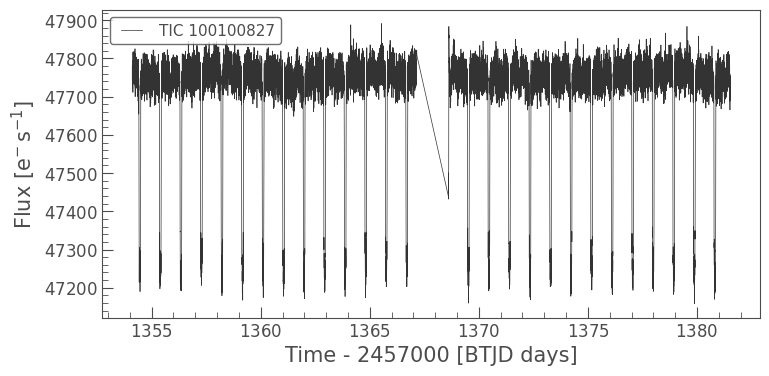

In [31]:
lc = search[0].download()   # download row 0 = Sector 2 (2018); lc = "light curve"
lc.plot()                   # plot brightness (electrons/sec) vs. time (days)

### Raw light curve (Sector 2)
- Y = light hitting the camera (~47,750 e⁻/s); X = time in days
- Big regular dips = planet passing in front of the star (transits)
- Period by eye: just under 1 day (~0.94 d)
- Gap near day 1368 = TESS pausing to send data to Earth (diagonal line isn't real data)
- Wiggles ±50 (~0.1%) = noise: random photon arrival, camera, star flicker
- Dip (~1%) is ~10× bigger than the noise → easy to see

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

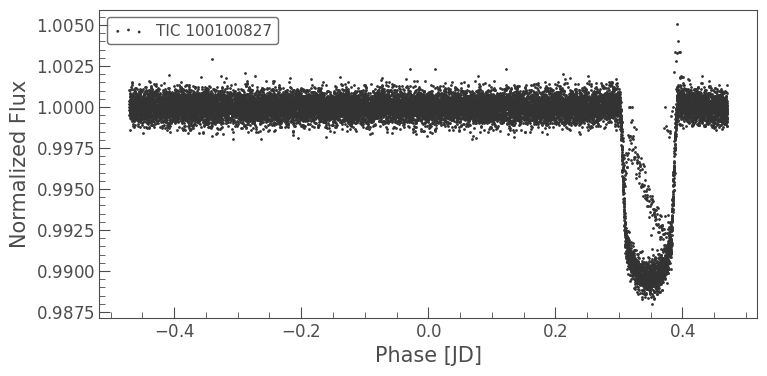

In [32]:
# flatten(): remove slow drifts and rescale so normal brightness = 1.000
# fold(): cut data into chunks one orbit long (0.9414526 days) and stack them
# scatter(): plot as dots instead of a line
lc.flatten().fold(period=0.9414526).scatter()

### Folded transit
- All ~27 transits stacked → noise averages out, true shape shows
- Depth ≈ 1.000 → 0.9895 ≈ 1.05% of the starlight blocked
  -  $\delta \approx (R_p/R_s)^2$ → planet size
- Duration ≈ phase 0.31 → 0.39 ≈ 0.08 days ≈ 2 hours
- Rounded (U-shaped) bottom = limb darkening (star dimmer at edges) → planet-like
- Dip sits at 0.35, not 0, because no transit time (epoch) was given yet
- Scatter above/below 1.000 = normal noise around the average

### Open questions
- Spike to ~1.005 right after the dip + faint trail inside the dip:
  likely flatten() distorting the transits → fix by masking transits before flattening

## Pipeline functions
Turning each step into a reusable function so it works on any star.

In [33]:
def radius_ratio(depth):
    """Return planet radius / star radius from transit depth.
    Physics: depth ≈ (Rp/Rs)^2  →  Rp/Rs = sqrt(depth)
    """
    return depth ** 0.5      # 0.5 power = square root

print(radius_ratio(0.0105))  # WASP-18 b
print(radius_ratio(0.0001))  # a much smaller dip
#100× smaller dip → only 10× smaller planet (depth ∝ radius²)

0.10246950765959599
0.01


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

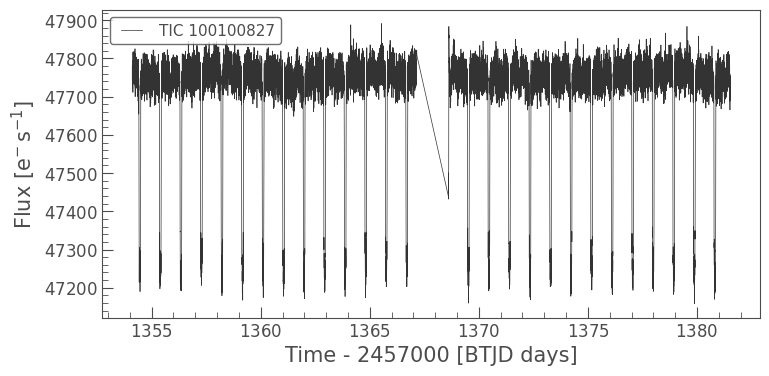

In [34]:
import lightkurve as lk

def download(star_name, sector_index=0):
    """Download one TESS light curve (2-minute data) for any star.
    sector_index picks which observation to use: 0 = the first one.
    """
    search = lk.search_lightcurve(star_name, mission="TESS",
                                  author="SPOC", exptime=120)
    lc = search[sector_index].download()
    return lc

lc = download("WASP-18")   # test it on our known planet
lc.plot()

In [35]:
def plain(x):
    """Turn an astropy/lightkurve value (with units or hidden masks) into a plain number."""
    return float(np.asarray(getattr(x, "value", x)))

def clean(lc, window_length=721, period=None, t0=None, duration=None, trim=0.25):
    """Remove bad points and slow drifts.
    If period/t0/duration are given, transits are masked (ignored) while smoothing.
    """
    lc = lc.remove_nans()
    lc = lk.LightCurve(time=lc.time,
                       flux=np.asarray(lc.flux.value),
                       flux_err=np.asarray(lc.flux_err.value))

    # NEW: cut the first `trim` days after each data gap (and at the sector start)
    t = np.asarray(lc.time.value, dtype=float)
    restarts = np.r_[t[0], t[1:][np.diff(t) > 0.5]]   # times when observing (re)starts
    keep = np.ones(len(t), dtype=bool)
    for start in restarts:
        keep &= ~((t >= start) & (t < start + trim))
    lc = lc[keep]

    lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))
    if period is None:
        mask = None
    else:
        P, T0, D = plain(period), plain(t0), plain(duration)
        t = np.asarray(lc.time.value, dtype=float)
        phase = (t - T0 + 0.5 * P) % P - 0.5 * P    # days from the nearest transit center
        mask = np.abs(phase) < 0.75 * D             # True = inside transit (1.5× duration wide)
    lc = lc.flatten(window_length=window_length, mask=mask)
    return lc

Period: 0.941794179417942 d
Transit time: 1354.4515072617191
Duration: 0.08 d
Depth: 0.009344622620092597


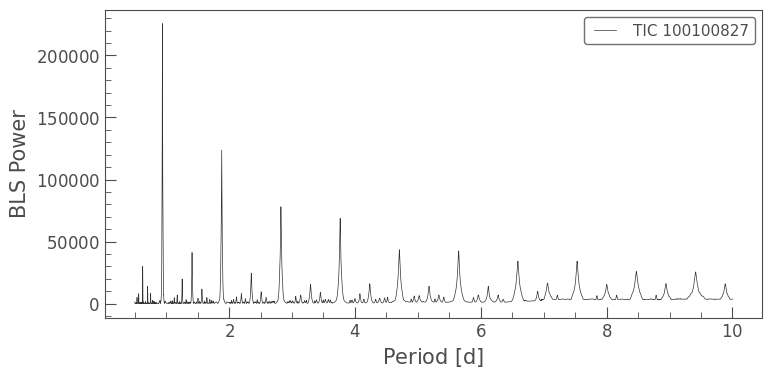

In [36]:
import numpy as np

def search(lc, min_period=0.5, max_period=10):
    """Search for repeating box-shaped dips (Box Least Squares).
    Returns: period, transit time, duration, depth of the strongest signal.
    """
    periods = np.linspace(min_period, max_period, 10000)    # 10,000 periods to try
    pg = lc.to_periodogram(method="bls", period=periods,
                           duration=[0.05, 0.08, 0.1, 0.15, 0.2])  # dip lengths to try (days)
    pg.plot()                                                # the periodogram
    return (pg.period_at_max_power,        # best period
            pg.transit_time_at_max_power,  # time of one transit (t0)
            pg.duration_at_max_power,      # dip length
            pg.depth_at_max_power)         # dip depth

period, t0, duration, depth = search(clean_lc)
print("Period:", period)
print("Transit time:", t0)
print("Duration:", duration)
print("Depth:", depth)

Depth: 0.010871465706867589
Rp/Rs: 0.10426632105750921


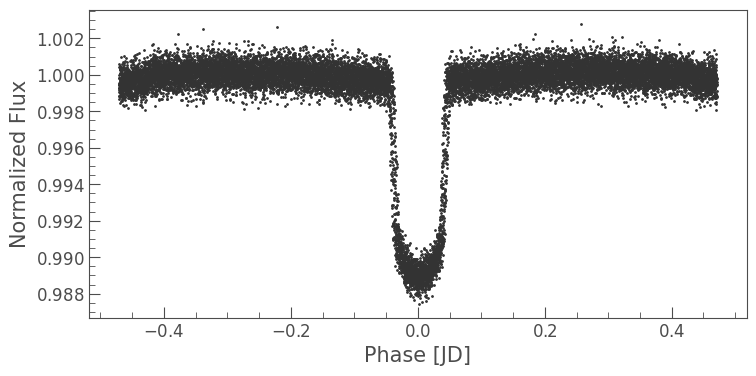

In [37]:
def measure(lc, period, t0, duration):
    """Fold at the found period (transit centered at 0) and measure the depth
    from the middle of the dip.
    """
    folded = lc.fold(period=plain(period), epoch_time=t0)
    folded.scatter()
    middle = folded[np.abs(folded.time.value) < 0.25 * plain(duration)]
    depth = 1 - np.median(middle.flux.value)
    return depth

clean_lc2 = clean(lc, period=period, t0=t0, duration=duration)
depth2 = measure(clean_lc2, period, t0, duration)
print("Depth:", depth2)
print("Rp/Rs:", radius_ratio(depth2))

### Masked clean + measure: results
- Masking transits before flattening fixed the problems from this morning:
  dip now centered at 0, faint trail gone, spike almost gone
- Depth (middle of dip) = 0.0109 → Rp/Rs = 0.104
- Published Rp/Rs ≈ 0.098 → mine is ~6% too big
- Why: the middle of the dip is where the planet blocks the star's brightest part
  (center). The simple formula $\delta \approx (R_p/R_s)^2$ assumes the star is
  equally bright everywhere, so it overestimates.

## Limb-darkened transit model
Fitting a realistic transit model (batman) that includes limb darkening:
$$\frac{I(\mu)}{I_{center}} = 1 - u_1(1-\mu) - u_2(1-\mu)^2$$
Goal: an accurate Rp/Rs, plus the orbit size (a/Rs) and tilt (inclination), with uncertainties.

In [38]:
!pip install batman-package -q
import batman
from scipy.optimize import curve_fit

# Fold the cleaned data, then keep only points near the transit (faster fitting)
folded = clean_lc2.fold(period=plain(period), epoch_time=t0)
x = np.asarray(folded.time.value, dtype=float)    # days from transit center
y = np.asarray(folded.flux.value, dtype=float)    # normalized brightness
near = np.abs(x) < 0.15
x, y = x[near], y[near]

In [39]:
def transit_model(x, rp, a, inc, u1, u2):
    """Predicted brightness at each time x for a planet with:
    rp  = planet radius / star radius
    a   = orbit radius / star radius
    inc = orbit tilt in degrees (90 = perfectly edge-on)
    u1, u2 = limb darkening strength
    """
    params = batman.TransitParams()
    params.t0 = 0.0                 # transit centered at 0 (we folded it that way)
    params.per = plain(period)      # orbital period (days)
    params.rp = rp
    params.a = a
    params.inc = inc
    params.ecc = 0.0                # circular orbit
    params.w = 90.0                 # orientation (doesn't matter if circular)
    params.u = [u1, u2]
    params.limb_dark = "quadratic"
    m = batman.TransitModel(params, x)
    return m.light_curve(params)

In [40]:
guess  = [0.10, 3.5, 85, 0.3, 0.2]                       # starting guesses
bounds = ([0.05, 1.5, 70, 0.0, -0.5],                    # lowest allowed values
          [0.20, 10.0, 90, 1.0,  1.0])                   # highest allowed values

popt, pcov = curve_fit(transit_model, x, y, p0=guess, bounds=bounds)
errs = np.sqrt(np.diag(pcov))                            # uncertainty on each value

names = ["Rp/Rs", "a/Rs", "inc (deg)", "u1", "u2"]
for name, val, err in zip(names, popt, errs):
    print(f"{name:10s} = {val:.4f} ± {err:.4f}")

Rp/Rs      = 0.1019 ± 0.0012
a/Rs       = 2.7405 ± 0.0279
inc (deg)  = 75.4865 ± 0.4250
u1         = 0.0000 ± 0.2632
u2         = 0.6151 ± 0.3687


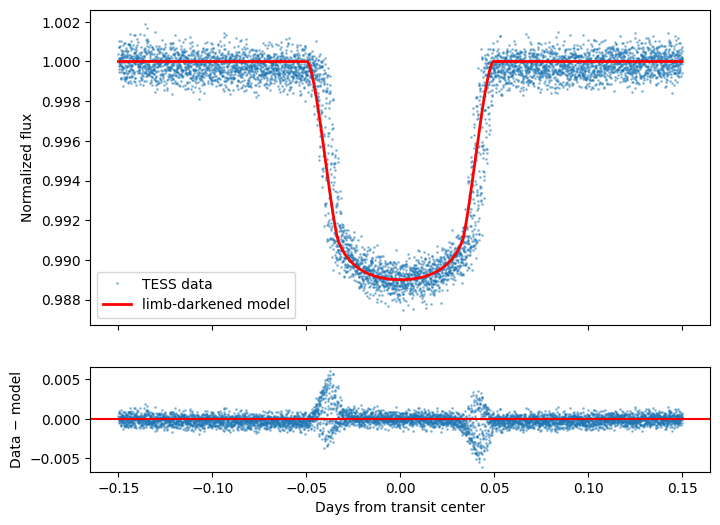

In [41]:
import matplotlib.pyplot as plt

order = np.argsort(x)
model = transit_model(x[order], *popt)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(x, y, ".", ms=2, alpha=0.4, label="TESS data")
ax1.plot(x[order], model, "r-", lw=2, label="limb-darkened model")
ax1.set_ylabel("Normalized flux"); ax1.legend()
ax2.plot(x[order], y[order] - model, ".", ms=2, alpha=0.4)
ax2.axhline(0, color="r")
ax2.set_xlabel("Days from transit center"); ax2.set_ylabel("Data − model")
plt.show()

### Diagnosing the first model fit
- The first fit's residuals (data − model) showed S-shaped wiggles at ingress/egress
  (±0.045 d) → a systematic mismatch, not random noise
- Fitted values were unphysical: a/Rs = 2.76 (expect ~3.5), inc = 75.8° (expect ~84°),
  and u1 stuck at its lower bound (0) → the fit was bending parameters to compensate
- Cause: the BLS period (0.94179 d) was ~0.00034 d too long. Over ~27 orbits that
  adds up to ~6 min of drift → transits don't stack perfectly when folded → smeared edges
- Fix: fit the UNFOLDED data and let the transit time (t0) and period vary too,
  so every transit is placed individually

In [42]:
# Unfolded data, keeping only points within 0.15 days of a transit
t_all = np.asarray(clean_lc2.time.value, dtype=float)
f_all = np.asarray(clean_lc2.flux.value, dtype=float)
P0, T00 = plain(period), plain(t0)
ph = (t_all - T00 + 0.5 * P0) % P0 - 0.5 * P0          # days from nearest transit
near = np.abs(ph) < 0.15
t_fit, f_fit = t_all[near], f_all[near]

def transit_model2(t, t0_, per, rp, a, inc, u1, u2):
    """Same transit model, but transit time and period are now fitted too."""
    params = batman.TransitParams()
    params.t0, params.per = t0_, per
    params.rp, params.a, params.inc = rp, a, inc
    params.ecc, params.w = 0.0, 90.0
    params.u, params.limb_dark = [u1, u2], "quadratic"
    return batman.TransitModel(params, t).light_curve(params)

guess2  = [T00, P0, 0.10, 3.5, 85, 0.3, 0.2]
bounds2 = ([T00 - 0.02, P0 - 0.002, 0.05, 1.5, 70, 0.0, -0.5],
           [T00 + 0.02, P0 + 0.002, 0.20, 10.0, 90, 1.0,  1.0])

popt2, pcov2 = curve_fit(transit_model2, t_fit, f_fit, p0=guess2, bounds=bounds2)
errs2 = np.sqrt(np.diag(pcov2))

names2 = ["t0", "period", "Rp/Rs", "a/Rs", "inc (deg)", "u1", "u2"]
for name, val, err in zip(names2, popt2, errs2):
    print(f"{name:10s} = {val:.5f} ± {err:.5f}")

t0         = 1354.45779 ± 0.00006
period     = 0.94146 ± 0.00000
Rp/Rs      = 0.09998 ± 0.00033
a/Rs       = 3.35854 ± 0.02667
inc (deg)  = 82.42849 ± 0.37586
u1         = 0.29617 ± 0.04803
u2         = 0.14497 ± 0.08317


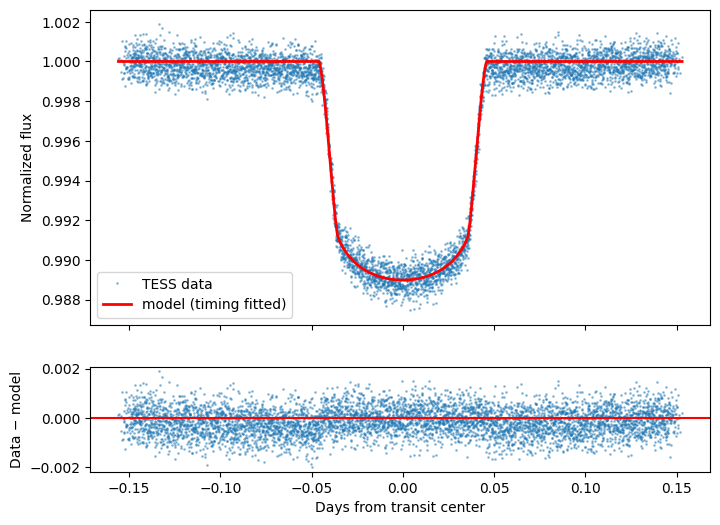

In [43]:
t0_fit, P_fit = popt2[0], popt2[1]
xph = (t_fit - t0_fit + 0.5 * P_fit) % P_fit - 0.5 * P_fit   # fold with FITTED timing
model2 = transit_model2(t_fit, *popt2)
order = np.argsort(xph)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(xph, f_fit, ".", ms=2, alpha=0.4, label="TESS data")
ax1.plot(xph[order], model2[order], "r-", lw=2, label="model (timing fitted)")
ax1.set_ylabel("Normalized flux"); ax1.legend()
ax2.plot(xph, f_fit - model2, ".", ms=2, alpha=0.4)
ax2.axhline(0, color="r")
ax2.set_xlabel("Days from transit center"); ax2.set_ylabel("Data − model")
plt.show()

### Results: limb-darkened model with fitted timing (TESS Sector 2)
(after trimming 0.25 d after each data gap to remove the TESS ramp)
| Parameter | Value |
|---|---|
| Period | 0.94146 d |
| Rp/Rs | 0.09998 ± 0.00033 |
| a/Rs | 3.359 ± 0.027 |
| Inclination | 82.4° ± 0.4° |
| u1, u2 | 0.30 ± 0.05, 0.14 ± 0.08 |

- Residuals are flat random scatter → the model describes the data well
- Rp/Rs fixed from 0.104 (simple formula) → 0.0999 (limb darkening included),
  close to the published ~0.098
- Removing the ramp points barely changed the values → the fit was robust;
  the trim protects every future star from the same glitch

### Investigating the stray points (+0.03 d, above the model)
Question: real star/spacecraft effect, or something my cleaning created?

Number of odd points: 0
Their times (BTJD): []


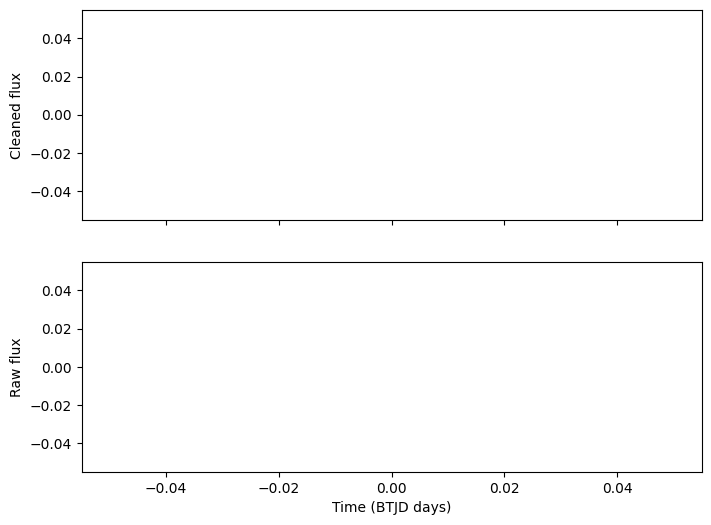

In [45]:
# 1. Find the points that sit far above the model
resid = f_fit - transit_model2(t_fit, *popt2)
odd = resid > 0.002                          # more than 0.2% above the model
print("Number of odd points:", odd.sum())
print("Their times (BTJD):", np.round(t_fit[odd], 3))

# 2. Zoom in on that moment: cleaned data vs. raw data
tc = np.median(t_fit[odd])                   # center of the odd points
raw_t = np.asarray(lc.time.value, dtype=float)
raw_f = np.asarray(lc.flux.value, dtype=float)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
z1 = (t_all > tc - 0.4) & (t_all < tc + 0.4)
ax1.plot(t_all[z1], f_all[z1], ".", ms=3)
ax1.axvline(tc, color="r", ls="--"); ax1.set_ylabel("Cleaned flux")
z2 = (raw_t > tc - 0.4) & (raw_t < tc + 0.4)
ax2.plot(raw_t[z2], raw_f[z2], ".", ms=3)
ax2.axvline(tc, color="r", ls="--"); ax2.set_ylabel("Raw flux")
ax2.set_xlabel("Time (BTJD days)")
plt.show()

### Result: the stray points are a TESS "ramp"
- All 15 odd points occur at 1368.605–1368.63, right after the mid-sector data gap
- Present in the RAW data too → instrumental, not created by my cleaning
- Observing resumed mid-transit; brightness then overshot (~1.002) and settled over ~0.1 d
  → the camera re-settling after the data downlink pause
- Fix: clean() now cuts the first 0.25 d after every data gap (applies to every star)

### Step 2: Star density from Kepler's 3rd law
Kepler: P² = 4π²a³/(G M★), and M★ = ρ★·(4/3)πR★³  →
$$\rho_\star = \frac{3\pi}{G P^2}\left(\frac{a}{R_\star}\right)^3$$
The transit fit gives P and a/R★, so the light curve alone measures the star's density.

In [46]:
G = 6.674e-11                      # gravitational constant (SI units)
P_sec = popt2[1] * 86400           # period: days → seconds
a_rs, a_err = popt2[3], errs2[3]   # fitted a/Rs and its uncertainty

rho = 3 * np.pi / (G * P_sec**2) * a_rs**3     # star density in kg/m³
rho_err = rho * 3 * a_err / a_rs               # error propagation (see below)

print(f"Star density = {rho/1000:.2f} ± {rho_err/1000:.2f} g/cm³")
print("For comparison: Sun = 1.41 g/cm³, water = 1.00 g/cm³")

Star density = 0.81 ± 0.02 g/cm³
For comparison: Sun = 1.41 g/cm³, water = 1.00 g/cm³


### Improving precision: combining 4 TESS sectors
a/R★ and inclination trade off (a more tilted, closer orbit makes a similar dip), and one
sector (~25 transits) can't fully separate them. More transits → less random error.
Using sectors 2, 3 (2018) and 29, 30 (2020).

Total data points: 60666


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

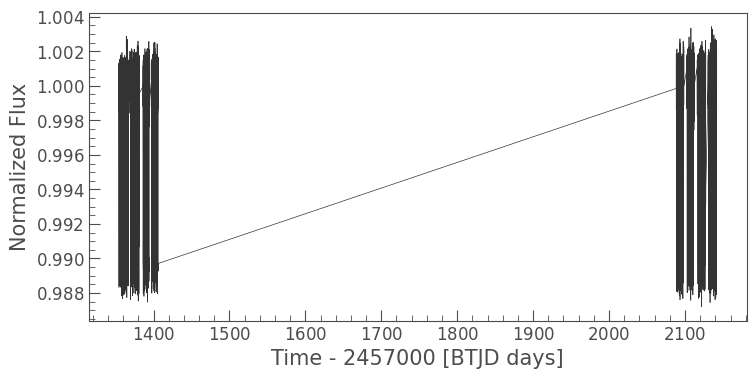

In [47]:
search_all = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC", exptime=120)
lcs = search_all[:4].download_all()          # first 4 rows = sectors 2, 3, 29, 30

# Clean each sector separately (masking transits using our fitted timing), then combine
cleaned_list = [clean(l, period=popt2[1], t0=popt2[0], duration=duration) for l in lcs]
multi = lk.LightCurveCollection(cleaned_list).stitch()
print("Total data points:", len(multi))
multi.plot()

In [48]:
t_all3 = np.asarray(multi.time.value, dtype=float)
f_all3 = np.asarray(multi.flux.value, dtype=float)
ph3 = (t_all3 - popt2[0] + 0.5 * popt2[1]) % popt2[1] - 0.5 * popt2[1]
near3 = np.abs(ph3) < 0.15
t_fit3, f_fit3 = t_all3[near3], f_all3[near3]

guess3  = list(popt2)                              # start from the 1-sector answer
bounds3 = ([popt2[0] - 0.01, popt2[1] - 0.0001, 0.05, 1.5, 70, 0.0, -0.5],
           [popt2[0] + 0.01, popt2[1] + 0.0001, 0.20, 10.0, 90, 1.0,  1.0])

popt3, pcov3 = curve_fit(transit_model2, t_fit3, f_fit3, p0=guess3, bounds=bounds3)
errs3 = np.sqrt(np.diag(pcov3))

for name, v1, e1, v3, e3 in zip(names2, popt2, errs2, popt3, errs3):
    print(f"{name:10s}  1 sector: {v1:.5f} ± {e1:.5f}   4 sectors: {v3:.5f} ± {e3:.5f}")

a3, a3_err = popt3[3], errs3[3]
rho3 = 3 * np.pi / (G * (popt3[1] * 86400)**2) * a3**3
print(f"\nStar density (4 sectors) = {rho3/1000:.2f} ± {rho3/1000 * 3 * a3_err / a3:.2f} g/cm³")

t0          1 sector: 1354.45779 ± 0.00006   4 sectors: 1354.45791 ± 0.00003
period      1 sector: 0.94146 ± 0.00000   4 sectors: 0.94145 ± 0.00000
Rp/Rs       1 sector: 0.09998 ± 0.00033   4 sectors: 0.09911 ± 0.00019
a/Rs        1 sector: 3.35854 ± 0.02667   4 sectors: 3.42105 ± 0.01671
inc (deg)   1 sector: 82.42849 ± 0.37586   4 sectors: 83.20370 ± 0.24635
u1          1 sector: 0.29617 ± 0.04803   4 sectors: 0.29192 ± 0.02522
u2          1 sector: 0.14497 ± 0.08317   4 sectors: 0.16750 ± 0.04535

Star density (4 sectors) = 0.85 ± 0.01 g/cm³


### Result: 4 sectors (2, 3, 29, 30)
| | 1 sector | 4 sectors |
|---|---|---|
| Period | 0.94146 | 0.94145 d |
| Rp/R★ | 0.0999 ± 0.0003 | 0.0991 ± 0.0002 |
| a/R★ | 3.359 ± 0.027 | 3.421 ± 0.017 |
| Inclination | 82.4° ± 0.4° | 83.2° ± 0.2° |
| ρ★ | 0.81 ± 0.02 | 0.85 ± 0.01 g/cm³ |

- 4× data → errors shrank ~1.6× and values moved toward published (a/R★ ~3.5, inc ~84°)
- a/R★ and inclination moved together → more data broke their tradeoff
- Density gap shrank from ~12% to ~7%. The remainder is likely systematic, not random:
  circular-orbit assumption (WASP-18 b is slightly eccentric) and limb darkening ↔
  inclination tradeoff. Possible next refinements: eccentric orbit, all 9 sectors.